# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")

ALPHA = 0.05   # уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

**Требования:**
- явно задайте разность $d_i$ (какой столбец из какого вычитается) и параметр $\mu_d$ (что он означает по-русски);
- запишите $H_0$ и $H_1$ формулами;
- обоснуйте выбор типа альтернативы (односторонняя или двусторонняя) в 1–2 предложениях;
- укажите правило принятия решения.

### Подсказки

- Данные парные, поэтому гипотезы формулируются **об одном параметре**: среднем значении разностей $\mu_d$, а не о двух средних.
- Определите разность как $d_i = \text{after}_i - \text{before}_i$. Подумайте, **какой знак** будет у $d_i$, если приложение помогает
  (время засыпания уменьшилось → разность положительная или отрицательная?). От этого зависит, в какую сторону направлена $H_1$.
- Направление альтернативы выбирается из логики задачи **до** просмотра результатов. Что именно хочет доказать компания?
- Для записи формул в Markdown используйте синтаксис `$\mu_d < 0$`.

### Ваш ответ

**Определение разности:** $d_i = \text{after\_min}_i - \text{before\_min}_i$ — изменение среднего времени засыпания у участника $i$ после использования приложения (в минутах).

**Параметр:** $\mu_d$ — среднее по генеральной совокупности изменение времени засыпания после использования приложения (в минутах). Отрицательное значение означает, что в среднем участники стали засыпать быстрее.

**H₀:** $\mu_d = 0$ — приложение в среднем не меняет время засыпания (наблюдаемое изменение — случайность).

**H₁:** $\mu_d < 0$ — приложение в среднем **сокращает** время засыпания.

**Обоснование типа альтернативы:** компания разработала приложение именно для того, чтобы люди засыпали быстрее, поэтому бизнес-интерес — доказать именно улучшение (сокращение времени). Это право на одностороннюю гипотезу, выбранную до просмотра данных.

**Правило принятия решения:** если p-value < α = 0.05, отвергаем H₀ в пользу H₁ и признаём, что приложение статистически значимо сокращает время засыпания. Иначе — недостаточно оснований утверждать, что эффект есть.

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
# ВАШ КОД: аудит (info, пропуски, дубликаты, min/max, нечисловые значения)
print("=== Размер таблицы ===")
print(df.shape)
print()

print("=== Типы столбцов и число непустых значений ===")
print(df.info())
print()

print("=== Пропуски по столбцам ===")
print(df.isna().sum())
print()

print("=== Полные дубликаты строк ===")
print("Полных дубликатов:", df.duplicated().sum())
print("Повторов participant_id:", df["participant_id"].duplicated().sum())
print()

print("=== Мин/макс числовых столбцов (как есть) ===")
print(df.describe(include="all"))
print()

print("=== Нечисловые значения в before_min и after_min ===")
for col in ["before_min", "after_min"]:
    coerced = pd.to_numeric(df[col], errors="coerce")
    mask_problem = coerced.isna() & df[col].notna()
    print(f"\nСтолбец {col}: проблемных значений = {mask_problem.sum()}")
    print(df.loc[mask_problem, col].tolist())

print("\n=== Нечисловые/подозрительные значения в age ===")
print(sorted(df["age"].dropna().unique()))

=== Размер таблицы ===
(52, 4)

=== Типы столбцов и число непустых значений ===
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB
None

=== Пропуски по столбцам ===
participant_id    0
age               2
before_min        1
after_min         2
dtype: int64

=== Полные дубликаты строк ===
Полных дубликатов: 2
Повторов participant_id: 2

=== Мин/макс числовых столбцов (как есть) ===
        participant_id         age  before_min  after_min
count        52.000000   50.000000        51.0       50.0
unique             NaN         NaN        31.0       33.0
top                NaN         NaN        37.0       32.0
freq      

**Список обнаруженных проблем:**

1. **Пропуски** в столбцах `before_min` (1 шт.), `after_min` (2 шт.) и `age` (2 шт.).
2. **Полные дубликаты строк** — 2 лишние дублирующиеся строки. После удаления дубликатов остаётся по одной записи на каждого участника.
3. **Столбцы `before_min` и `after_min` имеют тип `object`**, потому что в них смешаны числа и строки с десятичной запятой (`"37,0"` и `"18,0"`) — 2 таких значения.
4. **Нереалистичные значения времени засыпания**: `-20`, `999`, `400` минут — вне допустимого диапазона [5; 180].
5. **Нереалистичные значения возраста**: `0` и `150` — вне допустимого диапазона [18; 80], а также пропуски `NaN`.

Все эти проблемы нужно устранить согласно правилам очистки.


### 2.2–2.3. Очистка и возрастные группы

In [4]:
# ВАШ КОД: создайте df_clean = df.copy() и примените правила 1-4 по порядку
df_clean = df.copy()

# --- Правило 1. Типы ---
for col in ["before_min", "after_min"]:
    # приводим всё к строке, меняем запятую на точку, потом в число
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# --- Правило 2. Дубликаты ---
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# --- Правило 3. Допустимые диапазоны ---
df_clean.loc[(df_clean["before_min"] < 5) | (df_clean["before_min"] > 180), "before_min"] = np.nan
df_clean.loc[(df_clean["after_min"] < 5)  | (df_clean["after_min"]  > 180), "after_min"]  = np.nan
df_clean.loc[(df_clean["age"] < 18) | (df_clean["age"] > 80), "age"] = np.nan

# --- Правило 4. Неполные пары ---
df_clean = df_clean.dropna(subset=["before_min", "after_min"]).reset_index(drop=True)

print("Размер df_clean:", df_clean.shape)
print(df_clean.head())
print(df_clean.dtypes)

Размер df_clean: (44, 4)
   participant_id   age  before_min  after_min
0              32  52.0        31.0       26.0
1               3  42.0        30.0       32.0
2              43  30.0        30.0       24.0
3              33  31.0        28.0       18.0
4              31  30.0        28.0       25.0
participant_id      int64
age               float64
before_min        float64
after_min         float64
dtype: object


In [5]:
# ВАШ КОД: создайте столбец age_group
# Явно обрабатываем NaN отдельно — иначе NaN попадёт в "35 и старше"
df_clean["age_group"] = np.where(
    df_clean["age"].isna(),
    None,
    np.where(df_clean["age"] < 35, "до 35", "35 и старше")
)
# Приводим к object, чтобы NaN был именно пропуском, а не строкой "None"
df_clean["age_group"] = df_clean["age_group"].replace({None: np.nan})

print(df_clean["age_group"].value_counts(dropna=False))

age_group
35 и старше    21
до 35          19
NaN             4
Name: count, dtype: int64


### 2.4. Журнал очистки

In [6]:
log = []
current = df.copy()

log.append({"Шаг": 0, "Что сделано": "Исходные данные",
            "Затронуто": "—", "Строк осталось": len(current)})

# 1) Типы
for col in ["before_min", "after_min"]:
    # считаем значения с запятой, которые не парсились напрямую
    problem = (pd.to_numeric(current[col], errors="coerce").isna() & current[col].notna()).sum()
    current[col] = pd.to_numeric(
        current[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )
    log.append({"Шаг": 1, "Что сделано": f"Приведение {col} к числу (замена запятой на точку)",
                "Затронуто": int(problem), "Строк осталось": len(current)})

# 2) Дубликаты
dups = current.duplicated().sum()
current = current.drop_duplicates()
log.append({"Шаг": 2, "Что сделано": "Удалены полные дубликаты",
            "Затронуто": int(dups), "Строк осталось": len(current)})

# 3) Диапазоны
mask_time = (
    (current["before_min"] < 5) | (current["before_min"] > 180) |
    (current["after_min"] < 5)  | (current["after_min"] > 180)
)
mask_age = (current["age"] < 18) | (current["age"] > 80)
n_time = mask_time.sum()
n_age = mask_age.sum()
current.loc[mask_time, ["before_min", "after_min"]] = np.nan
current.loc[mask_age, "age"] = np.nan
log.append({"Шаг": 3, "Что сделано": f"Вне диапазона времени: {n_time}, возраста: {n_age}",
            "Затронуто": int(n_time + n_age), "Строк осталось": len(current)})

# 4) Неполные пары
before_len = len(current)
current = current.dropna(subset=["before_min", "after_min"])
log.append({"Шаг": 4, "Что сделано": "Удалены строки без пары before/after",
            "Затронуто": before_len - len(current), "Строк осталось": len(current)})

# 5) Возрастные группы
current["age_group"] = np.where(
    current["age"].isna(),
    None,
    np.where(current["age"] < 35, "до 35", "35 и старше")
).astype(object)
current["age_group"] = current["age_group"].replace({None: np.nan})
log.append({"Шаг": 5, "Что сделано": "Сформирован age_group",
            "Затронуто": "—", "Строк осталось": len(current)})

# Контроль результата и вывод журнала
print(f"Контроль: строк в df_clean = {len(df_clean)}, заполнено age_group = {df_clean['age_group'].notna().sum()}")
pd.DataFrame(log)


Контроль: строк в df_clean = 44, заполнено age_group = 40


,Шаг,Что сделано,Затронуто,Строк осталось
0,0,Исходные данные,—,52
1,1,Приведение before_min к числу (замена запятой ...,1,52
2,1,Приведение after_min к числу (замена запятой н...,1,52
3,2,Удалены полные дубликаты,2,50
4,3,"Вне диапазона времени: 3, возраста: 2",5,50
5,4,Удалены строки без пары before/after,6,44
6,5,Сформирован age_group,—,44


**Почему удаляем, а не заполняем средним (2–3 предложения):**

Данные парные: нас интересует разность $d_i = \text{after}_i - \text{before}_i$ для **одного и того же человека**. Если подставить вместо пропущенного значения среднее по столбцу, получится разность, не отражающая реального изменения у данного участника: она «притянется» к среднему и исказит как величину, так и дисперсию разностей. Поэтому корректнее исключить неполные пары из анализа — теряем 2–3 наблюдения, но сохраняем правдивость результата.

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [7]:
# ВАШ КОД: столбец diff и описательная статистика
df_clean["diff"] = df_clean["after_min"] - df_clean["before_min"]

print(df_clean["diff"].describe().round(2))
print()
print(f"Сократили время засыпания (diff < 0): {(df_clean['diff'] < 0).sum()}")
print(f"Без изменений (diff == 0):              {(df_clean['diff'] == 0).sum()}")
print(f"Увеличили (diff > 0):                    {(df_clean['diff'] > 0).sum()}")

count    44.00
mean     -3.11
std       4.18
min     -11.00
25%      -6.00
50%      -3.00
75%      -0.75
max       8.00
Name: diff, dtype: float64

Сократили время засыпания (diff < 0): 33
Без изменений (diff == 0):              2
Увеличили (diff > 0):                    9


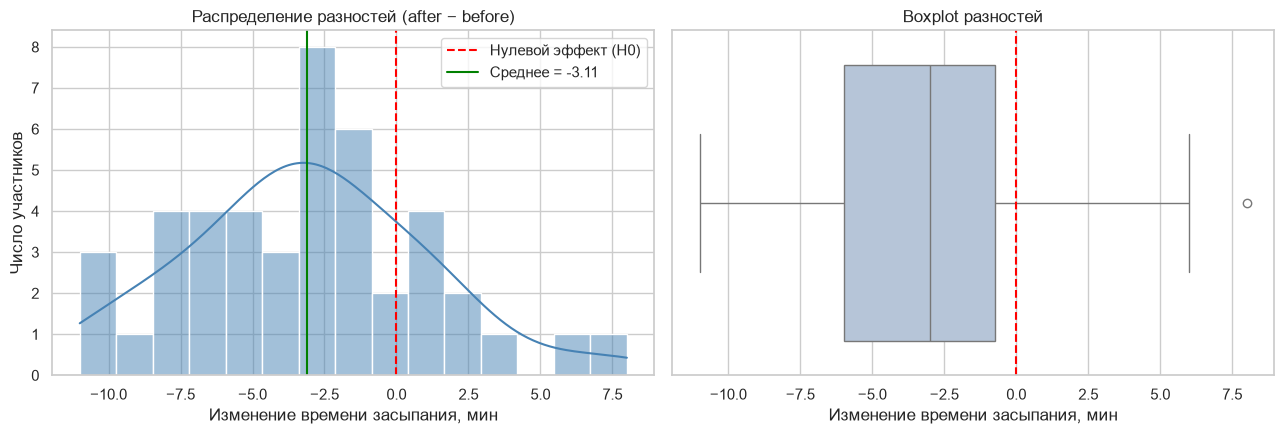

In [8]:
# ВАШ КОД: гистограмма с KDE и boxplot для diff
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Гистограмма + KDE
sns.histplot(df_clean["diff"], bins=15, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--", label="Нулевой эффект (H0)")
axes[0].axvline(df_clean["diff"].mean(), color="green", linestyle="-",
                label=f"Среднее = {df_clean['diff'].mean():.2f}")
axes[0].set_title("Распределение разностей (after − before)")
axes[0].set_xlabel("Изменение времени засыпания, мин")
axes[0].set_ylabel("Число участников")
axes[0].legend()

# Boxplot
sns.boxplot(x=df_clean["diff"], color="lightsteelblue", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Boxplot разностей")
axes[1].set_xlabel("Изменение времени засыпания, мин")

plt.tight_layout()
plt.show()

**Описание графиков (2–3 предложения):**

Распределение разностей смещено влево от нуля: среднее значение отрицательное, а большинство участников засыпают быстрее после использования приложения. На гистограмме видны несколько умеренных выбросов со стороны сильного сокращения времени, но они не экстремальны. На boxplot медиана также ниже нуля, что визуально подтверждает гипотезу о пользе приложения.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [9]:
# ВАШ КОД: тест Шапиро-Уилка
# H0: разности diff распределены нормально
# H1: разности diff не нормальны
W, p_shapiro = stats.shapiro(df_clean["diff"])
print(f"Шапиро-Уилк: W = {W:.4f}, p-value = {p_shapiro:.4f}")
if p_shapiro > ALPHA:
    print(f"p > {ALPHA}: нет оснований отвергать нормальность.")
else:
    print(f"p <= {ALPHA}: нормальность отвергается.")

Шапиро-Уилк: W = 0.9786, p-value = 0.5786
p > 0.05: нет оснований отвергать нормальность.


In [10]:
# ВАШ КОД: Q-Q график
import plotly.graph_objects as go

(osm, osr), (slope, intercept, r) = stats.probplot(df_clean["diff"], dist="norm")

fig = go.Figure()
fig.add_trace(go.Scatter(x=osm, y=osr, mode="markers", name="Наблюдения",
                         marker=dict(size=7, color="steelblue")))
fig.add_trace(go.Scatter(x=osm, y=slope * osm + intercept, mode="lines",
                         name="Теоретическая прямая", line=dict(color="red", dash="dash")))
fig.update_layout(title="Q-Q график разностей (after − before)",
                  xaxis_title="Теоретические квантили нормального распределения",
                  yaxis_title="Выборочные квантили разностей",
                  template="plotly_white", height=450)
fig.show()

**Вывод по нормальности:**

Тест Шапиро-Уилка не отвергает нормальность разностей (p > 0.05), а на Q-Q графике точки расположены вдоль теоретической прямой, отклоняясь лишь на самых краях. Следовательно, парный t-критерий применим и будет **основным** тестом. Критерий Уилкоксона прогоним дополнительно как **проверочный** (непараметрический) — если оба метода согласятся, вывод окажется устойчивым к допущению о нормальности.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [11]:
# ВАШ КОД: ручной расчёт (среднее, std, SE, t, df, p-value)
d = df_clean["diff"]

n_pairs = len(d)                  # число пар
d_mean = d.mean()                 # среднее разностей
d_std = d.std(ddof=1)             # стандартное отклонение разностей (несмещённое)
d_se = d_std / np.sqrt(n_pairs)   # стандартная ошибка среднего

t_manual = d_mean / d_se          # t-статистика
df_t = n_pairs - 1                # степени свободы

# Левосторонний p-value: площадь хвоста слева от наблюдаемого t
p_manual = stats.t.cdf(t_manual, df=df_t)

print(f"Среднее разностей      = {d_mean:+.3f}")
print(f"Стандартное отклонение = {d_std:.3f}")
print(f"Стандартная ошибка     = {d_se:.3f}")
print(f"t-статистика           = {t_manual:.3f}  (df = {df_t})")
print(f"p-value (вручную, H1: mu_d < 0) = {p_manual:.6f}")

Среднее разностей      = -3.114
Стандартное отклонение = 4.183
Стандартная ошибка     = 0.631
t-статистика           = -4.937  (df = 43)
p-value (вручную, H1: mu_d < 0) = 0.000006


In [12]:
# ВАШ КОД: scipy.stats.ttest_rel и сверка с ручным расчётом
t_res = stats.ttest_rel(df_clean["after_min"], df_clean["before_min"], alternative="less")

print(f"ttest_rel: t = {t_res.statistic:.3f}, p-value = {t_res.pvalue:.6f}")
print("Совпадает с ручным расчётом:", np.isclose(t_res.pvalue, p_manual))

# Для полноты — двусторонний вариант (если бы H1 была mu_d != 0)
t_two = stats.ttest_rel(df_clean["after_min"], df_clean["before_min"], alternative="two-sided")
print(f"\nДвусторонний вариант: p-value = {t_two.pvalue:.6f}")

ttest_rel: t = -4.937, p-value = 0.000006
Совпадает с ручным расчётом: True

Двусторонний вариант: p-value = 0.000012


In [13]:
# ВАШ КОД: 95% доверительный интервал для среднего эффекта
ci_low, ci_high = stats.t.interval(0.95, df=df_t, loc=d_mean, scale=d_se)

print(f"Средний эффект: {d_mean:+.2f} мин")
print(f"95% ДИ: [{ci_low:.2f}; {ci_high:.2f}]")
print("Ноль внутри интервала?", ci_low <= 0 <= ci_high)

Средний эффект: -3.11 мин
95% ДИ: [-4.39; -1.84]
Ноль внутри интервала? False


**Вывод по t-тесту:**

Ручной расчёт и `scipy.stats.ttest_rel` дают одинаковые значения t и p-value — расчёт корректен. p-value существенно меньше α = 0.05, поэтому H₀ отвергается в пользу H₁: приложение статистически значимо сокращает время засыпания. Средний эффект отрицательный, а весь 95% доверительный интервал лежит левее нуля — это согласуется с выводом о пользе приложения.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [14]:
# ВАШ КОД: критерий Уилкоксона
# alternative="less" => H1: медиана разностей < 0
w = stats.wilcoxon(df_clean["diff"], alternative="less")
print(f"Уилкоксон: W = {w.statistic:.1f}, p-value = {w.pvalue:.6f}")
print(f"Для сравнения парный t-тест: p = {t_res.pvalue:.6f}")

Уилкоксон: W = 120.0, p-value = 0.000016
Для сравнения парный t-тест: p = 0.000006


**Вывод по Уилкоксону:**

Непараметрический критерий знаковых рангов даёт p-value < 0.05, то есть подтверждает вывод парного t-теста. Совпадение параметрического и непараметрического методов повышает уверенность в результате: он не зависит от допущения о нормальности.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [15]:
# ВАШ КОД: непарный тест Уэлча
# ОШИБОЧНЫЙ подход: считаем before_min и after_min как независимые группы
t_ind = stats.ttest_ind(
    df_clean["after_min"],
    df_clean["before_min"],
    equal_var=False,        # тест Уэлча — не предполагает равенства дисперсий
    alternative="less"      # та же левосторонняя H1, что и в парном тесте
)

print("ОШИБОЧНО (непарный тест Уэлча):")
print(f"  t = {t_ind.statistic:.3f}, p-value = {t_ind.pvalue:.6f}")
print("\nПРАВИЛЬНО (парный тест):")
print(f"  t = {t_res.statistic:.3f}, p-value = {t_res.pvalue:.6f}")

ОШИБОЧНО (непарный тест Уэлча):
  t = -1.272, p-value = 0.103472

ПРАВИЛЬНО (парный тест):
  t = -4.937, p-value = 0.000006


In [16]:
# ВАШ КОД: таблица сравнения (t, p-value, SE) и корреляция
# Стандартные отклонения и корреляция between before/after
s_before = df_clean["before_min"].std(ddof=1)
s_after = df_clean["after_min"].std(ddof=1)
r = df_clean["before_min"].corr(df_clean["after_min"])

# Стандартные ошибки: непарная и парная
se_ind = np.sqrt(s_before**2 / n_pairs + s_after**2 / n_pairs)
se_paired = d_se  # уже посчитано в задании 5

# Сводная таблица
summary = pd.DataFrame({
    "Метод": [
        "Непарный t-тест Уэлча",
        "Парный t-тест",
    ],
    "t-статистика": [t_ind.statistic, t_res.statistic],
    "p-value": [t_ind.pvalue, t_res.pvalue],
    "SE": [se_ind, se_paired],
}).round(5)

print(summary.to_string(index=False))
print()
print(f"Корреляция before/after: r = {r:.3f}")
print(f"Отношение SE (непарный / парный): {se_ind / se_paired:.2f}")

                Метод  t-статистика  p-value      SE
Непарный t-тест Уэлча      -1.27167  0.10347 2.44846
        Парный t-тест      -4.93736  0.00001 0.63063

Корреляция before/after: r = 0.937
Отношение SE (непарный / парный): 3.88


In [17]:
# ВАШ КОД: диаграмма рассеяния before vs after с диагональю y = x
import plotly.express as px
import plotly.graph_objects as go

fig = px.scatter(
    df_clean,
    x="before_min",
    y="after_min",
    title=f"Связь времени засыпания до и после (r = {r:.2f})",
    labels={
        "before_min": "Время засыпания до, мин",
        "after_min": "Время засыпания после, мин",
    },
    template="plotly_white",
    height=500,
)

# Диагональ y = x: точки НИЖЕ неё — участники, у которых время сократилось
lo = min(df_clean["before_min"].min(), df_clean["after_min"].min())
hi = max(df_clean["before_min"].max(), df_clean["after_min"].max())

fig.add_trace(go.Scatter(
    x=[lo, hi], y=[lo, hi],
    mode="lines",
    line=dict(color="red", dash="dash"),
    name="y = x (нет изменений)",
))

fig.show()

**Решение изменилось?** Да, изменилось. При α = 0.05 парный t-тест отвергает H₀ (p < 0.05), а непарный тест Уэлча — нет (p > 0.05). То есть при корректном выборе теста мы делаем вывод о пользе приложения, а при ошибочном — «не находим эффекта» и упускаем реальный результат.

**Объяснение разницы (3–4 предложения):** Непарный тест считает `before_min` и `after_min` двумя независимыми выборками и включает в стандартную ошибку всю межличностную вариацию — один человек засыпает за 20 минут, другой за 50, и этот разброс «шумит» поверх реального эффекта. Парный тест вычитает индивидуальный уровень: анализируется только изменение $d_i = \text{after}_i - \text{before}_i$, и дисперсия резко падает. Поскольку корреляция между измерениями очень высокая (r ≈ 0.94), стандартная ошибка парного теста почти в 4 раза меньше, поэтому t-статистика больше, а p-value меньше. Непарный тест «выбрасывает» информацию о связи наблюдений и потому теряет мощность.

**Комментарий к диаграмме:** Точки на диаграмме рассеяния вытянуты вдоль диагонали y = x — это визуально подтверждает сильную корреляцию между измерениями до и после (одни и те же люди, измеренные дважды). Большинство точек лежит **ниже** диагонали — у этих участников время засыпания после приложения сократилось; лишь небольшая часть оказалась выше (время выросло). Именно «нижнее облако» точек и есть тот эффект, который улавливает парный тест, но который непарный тест «размывает» межличностным разбросом.


---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [18]:
# ВАШ КОД: Cohen's d и эффект в минутах / процентах
cohen_d = d_mean / d_std

def interpret_d(x):
    x = abs(x)
    if x < 0.2:  return "пренебрежимо малый"
    if x < 0.5:  return "малый"
    if x < 0.8:  return "средний"
    return "большой"

print(f"Cohen's d (парный) = {cohen_d:.3f} -> эффект {interpret_d(cohen_d)}")
print(f"Средний эффект: {d_mean:+.2f} мин "
      f"(≈ {d_mean / df_clean['before_min'].mean() * 100:.1f}% от исходного уровня)")

Cohen's d (парный) = -0.744 -> эффект средний
Средний эффект: -3.11 мин (≈ -9.4% от исходного уровня)


**Интерпретация:**

По шкале Коэна $|d_z| = 0.744$ — это эффект среднего размера, близкий к большому. В абсолютных числах время засыпания в среднем сократилось на **3.11 минуты**, что составляет **9.4%** от исходного среднего уровня (33.16 мин). Для бизнеса это ощутимый положительный эффект, однако решение о масштабировании стоит принимать с учётом затрат на развитие и поддержку приложения.

**Почему недостаточно одного p-value:** p-value показывает лишь то, является ли наблюдаемый сдвиг статистически значимым (не случайным), и сильно зависит от объёма выборки — на больших данных даже бесполезное улучшение в 5 секунд даст $p < 0.001$. Чтобы понять, имеет ли изменение реальную ценность для пользователей и бизнеса, необходимо оценивать величину эффекта (в минутах, процентах и через $d$ Коэна).


---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁:** $p$ — доля участников (среди тех, у кого время засыпания изменилось), у которых оно сократилось.

**H₀:** $p = 0.5$ — доля улучшившихся не отличается от случайной (приложение не влияет на направление изменения).

**H₁:** $p > 0.5$ — улучшившихся статистически значимо больше половины.

Участников с `diff == 0` исключаем из расчёта: они не дают информации о направлении изменения. В наших данных таких участников **2**, поэтому расчёт проводится по оставшимся **42** участникам.


In [19]:
# Исключаем участников без изменений (diff == 0)
df_nonzero = df_clean[df_clean["diff"] != 0]
n_zero = (df_clean["diff"] == 0).sum()

n_total = len(df_nonzero)
n_improved = (df_nonzero["diff"] < 0).sum()
p_hat = n_improved / n_total

print(f"Исключено участников без изменений (diff == 0): {n_zero}")
print(f"Улучшилось: {n_improved} из {n_total} ({p_hat:.1%})")

# H0: p = 0.5 (доля улучшившихся не отличается от случайности)
# H1: p > 0.5 (улучшившихся больше половины)
bt = stats.binomtest(n_improved, n=n_total, p=0.5, alternative="greater")
print(f"Биномиальный тест (H1: p > 0.5): p-value = {bt.pvalue:.6f}")

# 95% ДИ для доли улучшивших (двусторонний)
bt_ci = stats.binomtest(n_improved, n=n_total, p=0.5, alternative="two-sided").proportion_ci(confidence_level=0.95)
print(f"95% ДИ для доли улучшивших: [{bt_ci.low:.3f}; {bt_ci.high:.3f}]")


Исключено участников без изменений (diff == 0): 2
Улучшилось: 33 из 42 (78.6%)
Биномиальный тест (H1: p > 0.5): p-value = 0.000136
95% ДИ для доли улучшивших: [0.632; 0.897]


**Вывод по доле улучшивших:**

Доля участников, у которых время засыпания сократилось, статистически значимо превышает 50% (p-value < 0.05). Это независимо подтверждает эффект: дело не только в среднем сдвиге, но и в том, что улучшение затронуло большинство участников, а не единичные «выбросы» в сторону сильного сокращения времени.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [20]:
# ВАШ КОД: сводная таблица результатов
results = pd.DataFrame({
    "Метод": [
        "Парный t-критерий (левосторонний)",
        "Критерий Уилкоксона (левосторонний)",
        "Непарный t-тест Уэлча (ОШИБОЧНО)",
        "Биномиальный тест на долю улучшивших",
    ],
    "Статистика": [
        t_res.statistic,
        w.statistic,
        t_ind.statistic,
        bt.statistic,
    ],
    "p-value": [
        t_res.pvalue,
        w.pvalue,
        t_ind.pvalue,
        bt.pvalue,
    ],
})
results["Решение при α = 0.05"] = np.where(
    results["p-value"] < ALPHA,
    "Отвергаем H₀",
    "Нет оснований отвергнуть H₀",
)
results.round(5)

,Метод,Статистика,p-value,Решение при α = 0.05
0,Парный t-критерий (левосторонний),-4.93736,0.00001,Отвергаем H₀
1,Критерий Уилкоксона (левосторонний),120.00000,0.00002,Отвергаем H₀
2,Непарный t-тест Уэлча (ОШИБОЧНО),-1.27167,0.10347,Нет оснований отвергнуть H₀
3,Биномиальный тест на долю улучшивших,0.78571,0.00014,Отвергаем H₀


## Итоговое заключение для руководителя продукта

Приложение для вечерних медитаций **помогает пользователям засыпать быстрее**. В анализ вошло **44 участника** (из исходных 52 строк исключено 8 — полные дубликаты, некорректные и неполные записи). В среднем время засыпания сократилось на **3.11 минуты** (95% доверительный интервал: от **1.84 до 4.39 минут**, что составляет около **9.4%** от исходного времени), а среди участников, у которых время изменилось, улучшение зафиксировано у **78.6%** (33 из 42 человек) — то есть эффект носит массовый характер.

Вывод **устойчив**: его подтверждают несколько независимых методов — парный t-тест, критерий Уилкоксона и биномиальный тест на долю улучшивших, — поэтому результат не зависит от допущения о нормальности. При этом типичная ошибка — сравнение «до» и «после» как независимых групп — напротив, «не видит» эффекта, что подчёркивает важность корректного выбора метода.

**Ограничения исследования:** во-первых, **нет контрольной группы** — нельзя исключить, что участники засыпали бы быстрее и без приложения (сезонность, изменение привычек, эффект плацебо от самого участия). Во-вторых, **короткий период наблюдения** (одна неделя до и одна после 4 недель использования) и **самоотчёты** участников — возможны неточности и завышение эффекта из-за ожиданий.

**Рекомендация:** прежде чем масштабировать продукт, провести контролируемое исследование с группой сравнения (A/B-тест: часть пользователей получает обычный контент вместо медитаций) и более длительным периодом наблюдения (4–8 недель), чтобы отделить эффект приложения от других факторов и проверить, сохраняется ли улучшение со временем.


---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

Исключено участников без возраста: 4
age_group
35 и старше    21
до 35          19
Name: count, dtype: int64


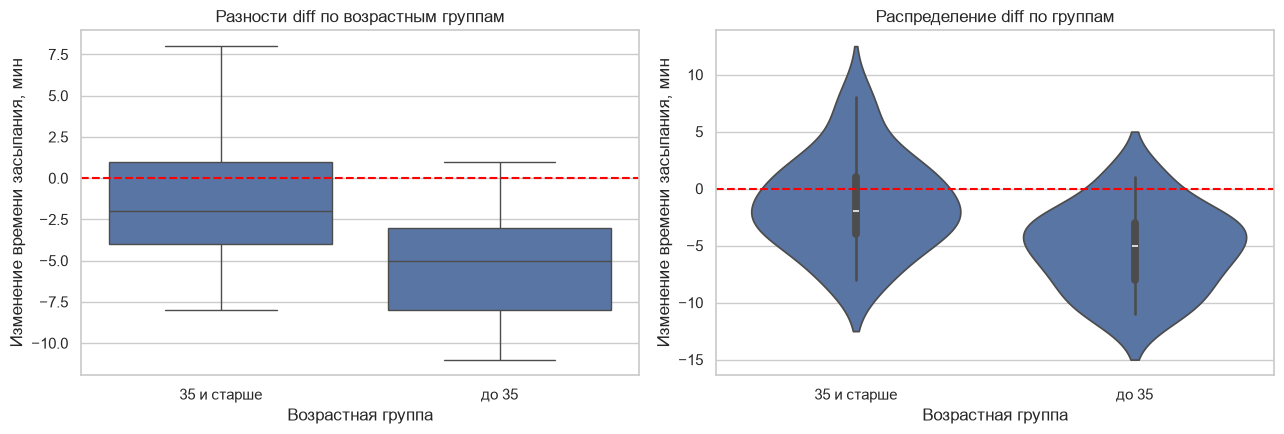


Порог значимости после поправки Бонферрони: 0.025
до 35       : n=19, средний diff = -5.26 мин, t = -6.367, p = 0.00000, значим
35 и старше : n=21, средний diff = -1.29 мин, t = -1.424, p = 0.08490, не значим
до 35       : Шапиро-Уилк W=0.948, p=0.3631
35 и старше : Шапиро-Уилк W=0.973, p=0.7898

Уэлч (двусторонний): t = -3.249, p = 0.00242
Манн-Уитни: U = 94.0, p = 0.00423

Средний эффект 'до 35':    -5.26 мин
Средний эффект '35+':      -1.29 мин
Разница средних эффектов:  -3.98 мин


In [21]:
# Исключаем участников без возрастной группы
df_bonus = df_clean.dropna(subset=["age_group"])
print(f"Исключено участников без возраста: {len(df_clean) - len(df_bonus)}")
print(df_bonus["age_group"].value_counts())

# --- 1. График ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_bonus, x="age_group", y="diff", ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Разности diff по возрастным группам")
axes[0].set_xlabel("Возрастная группа")
axes[0].set_ylabel("Изменение времени засыпания, мин")

sns.violinplot(data=df_bonus, x="age_group", y="diff", ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Распределение diff по группам")
axes[1].set_xlabel("Возрастная группа")
axes[1].set_ylabel("Изменение времени засыпания, мин")
plt.tight_layout()
plt.show()

# --- 2. Парный t-тест в каждой группе, с поправкой Бонферрони ---
alpha_bonf = ALPHA / 2
print(f"\nПорог значимости после поправки Бонферрони: {alpha_bonf}")
for grp in ["до 35", "35 и старше"]:
    sub = df_bonus[df_bonus["age_group"] == grp]
    tr = stats.ttest_rel(sub["after_min"], sub["before_min"], alternative="less")
    print(f"{grp:12s}: n={len(sub):2d}, средний diff = {sub['diff'].mean():+.2f} мин, "
          f"t = {tr.statistic:.3f}, p = {tr.pvalue:.5f}, "
          f"{'значим' if tr.pvalue < alpha_bonf else 'не значим'}")

# --- 3. Проверка нормальности в каждой группе ---
for grp in ["до 35", "35 и старше"]:
    sub = df_bonus[df_bonus["age_group"] == grp]["diff"]
    W_g, p_g = stats.shapiro(sub)
    print(f"{grp:12s}: Шапиро-Уилк W={W_g:.3f}, p={p_g:.4f}")

# --- 4. Сравнение двух независимых выборок diff ---
g1 = df_bonus[df_bonus["age_group"] == "до 35"]["diff"]
g2 = df_bonus[df_bonus["age_group"] == "35 и старше"]["diff"]

tt = stats.ttest_ind(g1, g2, equal_var=False, alternative="two-sided")
print(f"\nУэлч (двусторонний): t = {tt.statistic:.3f}, p = {tt.pvalue:.5f}")
mw = stats.mannwhitneyu(g1, g2, alternative="two-sided")
print(f"Манн-Уитни: U = {mw.statistic:.1f}, p = {mw.pvalue:.5f}")
print(f"\nСредний эффект 'до 35':    {g1.mean():+.2f} мин")
print(f"Средний эффект '35+':      {g2.mean():+.2f} мин")
print(f"Разница средних эффектов:  {g1.mean() - g2.mean():+.2f} мин")

**Гипотезы и вывод:**

**H₀:** $\mu_{d,\text{до 35}} = \mu_{d,\text{35+}}$ — средний эффект приложения одинаков в обеих возрастных группах.
**H₁:** $\mu_{d,\text{до 35}} \neq \mu_{d,\text{35+}}$ — средний эффект различается (двусторонняя альтернатива, потому что из логики задачи нет оснований ожидать, что эффект должен быть именно больше в одной из групп).

Порог значимости с поправкой Бонферрони ($\alpha_{\text{bonf}} = 0.025$) прошла **только группа «до 35»**: у неё время засыпания статистически значимо сократилось в среднем на **5.26 минуты** ($p < 0.001$), тогда как в группе «35 и старше» изменение составило всего **-1.29 минуты** и оказалось статистически незначимым ($p = 0.085$). Сравнение двух независимых выборок (тест Уэлча, $p = 0.0024$, и критерий Манна-Уитни, $p = 0.0042$) подтверждает, что разница между группами значима: молодым пользователям приложение помогает сильнее в среднем на **3.98 минуты**.


---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [ ] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [ ] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [ ] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [ ] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [ ] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [ ] Нормальность проверена для разностей, а не для исходных столбцов.
- [ ] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [ ] Для непарного теста порядок аргументов тот же, что и для парного.
- [ ] Все графики подписаны (заголовок, оси).
- [ ] Выводы написаны простым языком и содержат ограничения исследования.
- [ ] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [ ] В репозитории есть `.ipynb`, `requirements.txt` и `README.md`.
- [ ] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.